# 10.2 Redes de dutos

## 10.2.1 Dois trechos de dutos em série
Dois dutos de 500 m (25 elementos cada), cenário de 10.1.1, diferenças finitas
centrais. Formulação A: trechos ligados por especificação de **conexão**
(pressão do vértice a montante = pressão do 1º nó do trecho a jusante; vazões do
vértice a jusante = vazões do último nó do trecho a montante). Formulação B:
trechos acoplados por **vértice dinâmico** (tipo A). Figuras 10.20 a 10.24 e
Tabelas 10.2 e 10.3.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe, plot_vertices
from mfsim.plotting import compare_runs, legacy_pipe_dict

describe("10.2.1A")
caseA, rawA, resA = run_case("10.2.1A")
compare_states(resA, rawA)
describe("10.2.1B")
caseB, rawB, resB = run_case("10.2.1B")
compare_states(resB, rawB)

10.2.1 Dois trechos em série (formulação A: conexão)
Dois dutos de 500 m (25 elementos cada) ligados por especificação de conexão; cenário de 10.1.1; diferenças finitas centrais.
Figuras da tese: Figs. 10.20-10.24, Tabelas 10.2-10.3


[implicit BDF] steps=150 rejected=4 rhs=798 jac=8 | 0.2s
tempo de CPU: 0.25 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    4.19e-05       5.47e-02   7.66e-04
   1 twofluid     PT        3.49e-06       5.57e-04   6.27e-03
   1 twofluid     qL        4.10e-04       1.46e-01   2.81e-03
   1 twofluid     qG        8.78e-05       2.99e-02   2.93e-03
   2 twofluid     alphaG    4.03e-05       2.94e-02   1.37e-03
   2 twofluid     PT        1.05e-06       4.14e-04   2.53e-03
   2 twofluid     qL        4.22e-04       1.46e-01   2.89e-03
   2 twofluid     qG        1.07e-04       2.51e-02   4.24e-03
10.2.1 Dois trechos em série (formulação B: vértice dinâmico)
Dois dutos de 500 m acoplados por vértice dinâmico (tipo A).
Figuras da tese: Figs. 10.20-10.24


[implicit BDF] steps=150 rejected=5 rhs=833 jac=8 | 0.3s
tempo de CPU: 0.26 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    4.19e-05       5.46e-02   7.67e-04
   1 twofluid     PT        3.49e-06       5.57e-04   6.27e-03
   1 twofluid     qL        4.09e-04       1.46e-01   2.80e-03
   1 twofluid     qG        8.60e-05       2.99e-02   2.87e-03
   2 twofluid     alphaG    4.01e-05       2.82e-02   1.42e-03
   2 twofluid     PT        8.94e-07       3.97e-04   2.25e-03
   2 twofluid     qL        4.20e-04       1.46e-01   2.87e-03
   2 twofluid     qG        1.04e-04       2.54e-02   4.09e-03
vértices dinâmicos: máx |dif| = [3.21024671e-05 1.04248928e-06]


### Figuras 10.20-10.23: fração de gás, pressão e vazões nos dois trechos (formulação A)

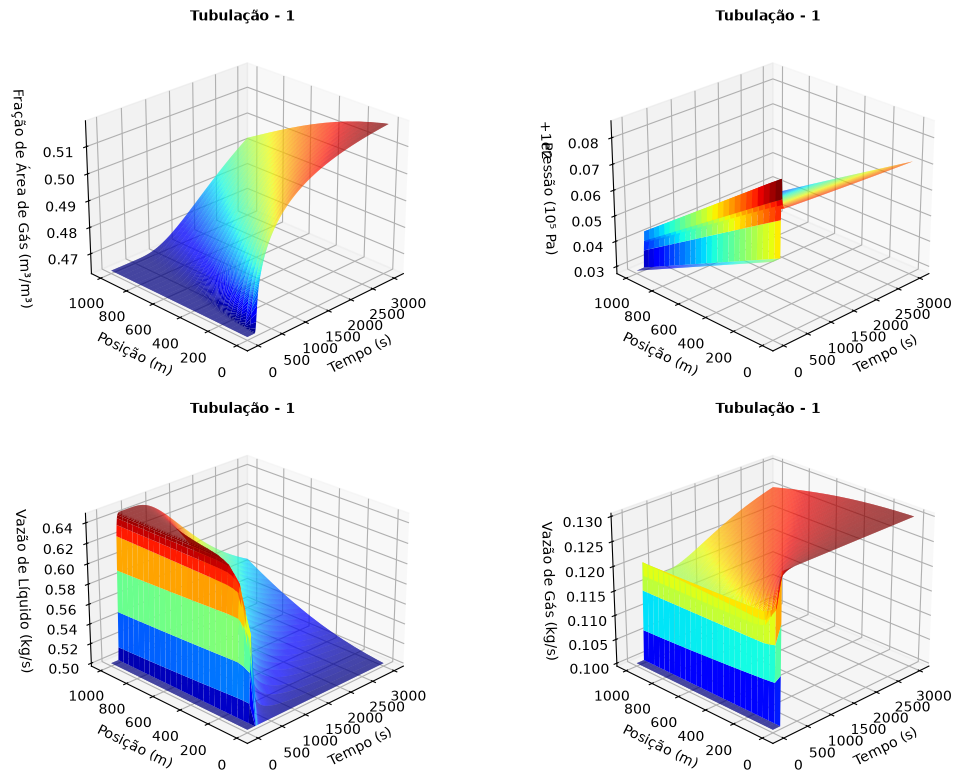

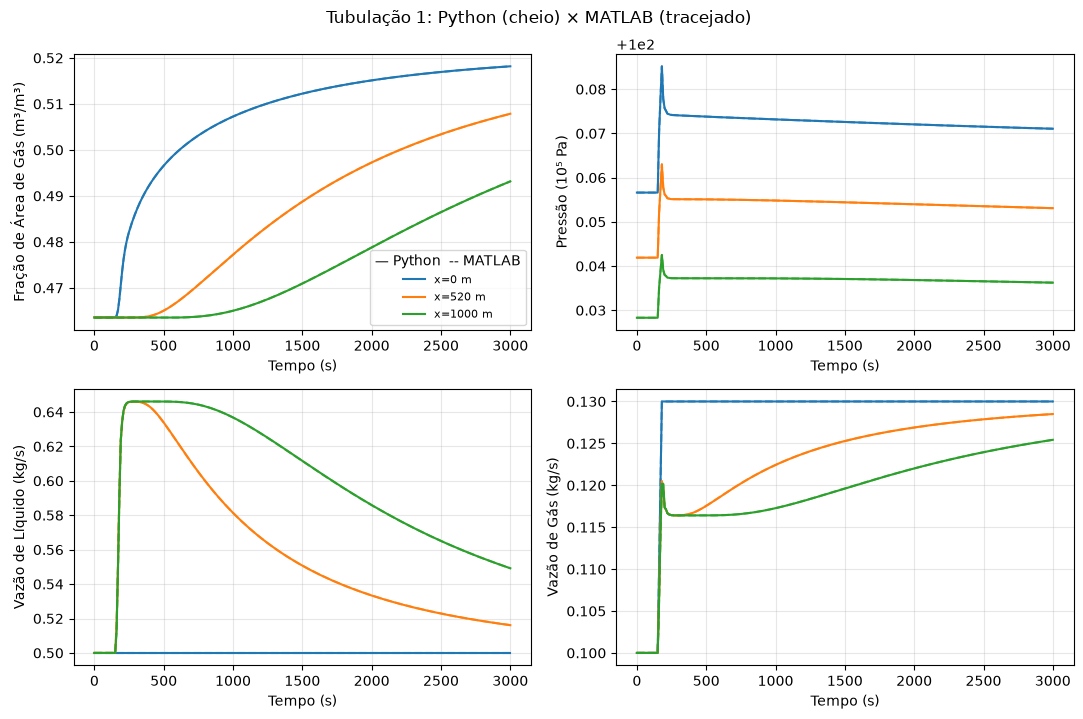

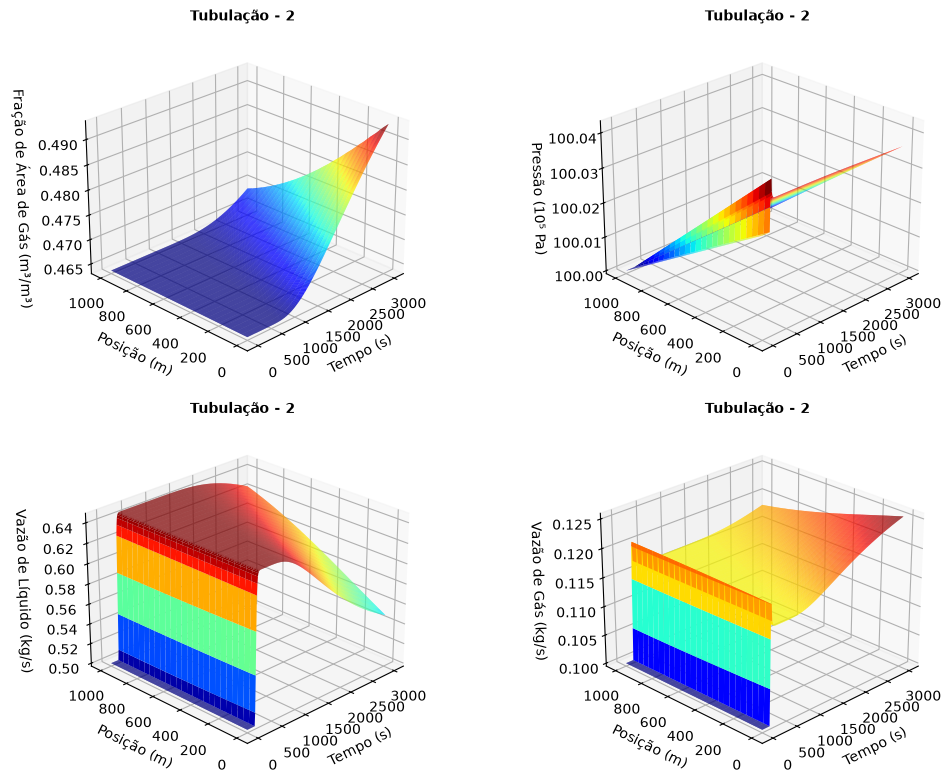

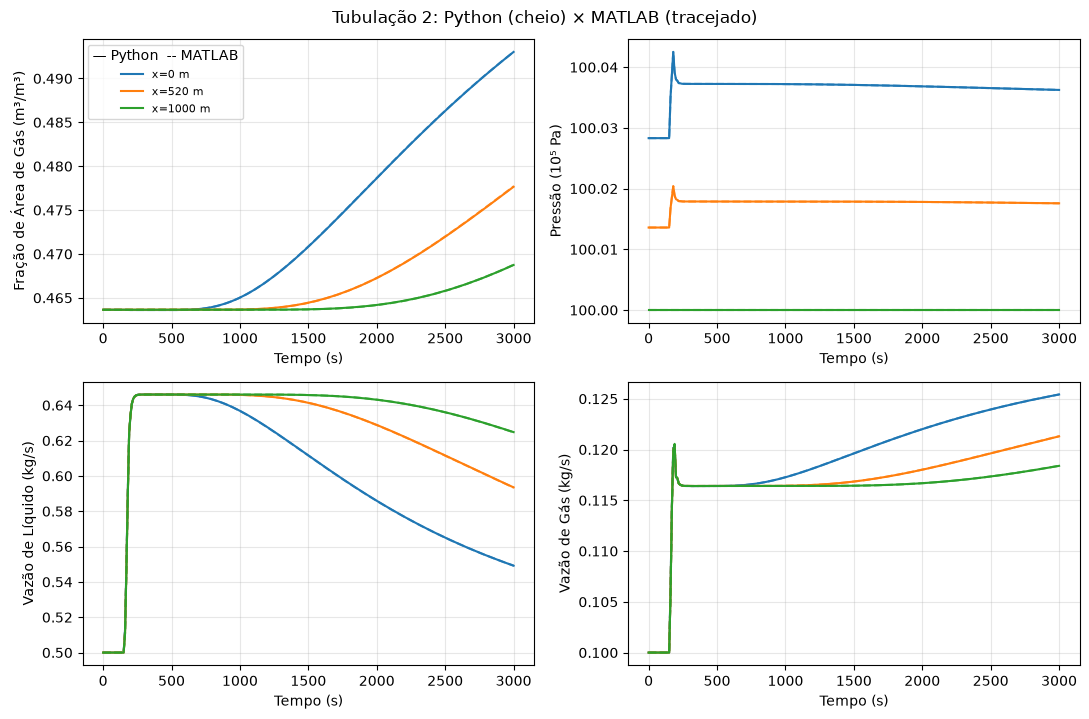

In [2]:
for k in (0, 1):
    show_pipe(resA, rawA, k)

### Formulação A × formulação B (saída do trecho 2)

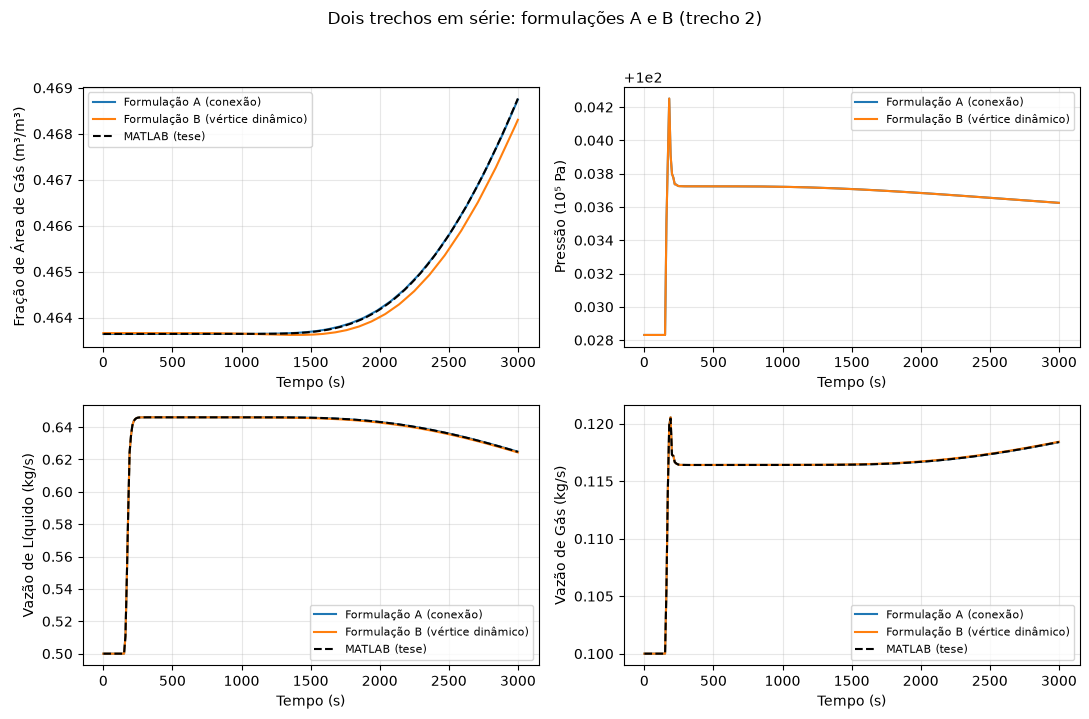

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs({"Formulação A (conexão)": resA, "Formulação B (vértice dinâmico)": resB}, k=1, key=key,
                 node=-1 if key != "P_bar" else 0, ax=ax, legacy=legacy_pipe_dict(rawA, 1) if key != "P_bar" else None)
fig.suptitle("Dois trechos em série: formulações A e B (trecho 2)", y=1.02); fig.tight_layout(); plt.show()

### Fechamento do balanço de massa no vértice de acoplamento (Figura 10.24, Tabela 10.3)

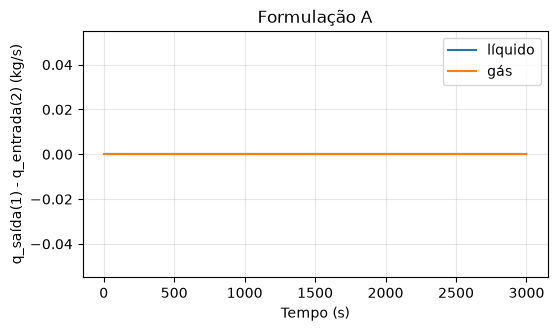

Formulação A - Tabela 10.3
 t (s)  qL saída 1  qL entrada 2  qG saída 1  qG entrada 2
     0       0.500         0.500       0.100         0.100
   750       0.644         0.644       0.117         0.117
  1000       0.637         0.637       0.117         0.117
  2000       0.586         0.586       0.122         0.122
  3000       0.549         0.549       0.125         0.125


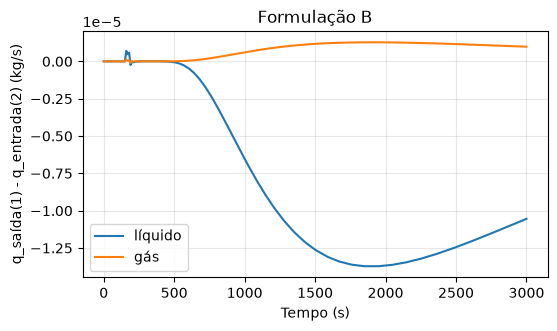

Formulação B - Tabela 10.3
 t (s)  qL saída 1  qL entrada 2  qG saída 1  qG entrada 2
     0       0.500         0.500       0.100         0.100
   750       0.644         0.644       0.117         0.117
  1000       0.637         0.637       0.117         0.117
  2000       0.586         0.586       0.122         0.122
  3000       0.549         0.549       0.125         0.125


In [4]:
for label, res in (("A", resA), ("B", resB)):
    p1, p2 = res.pipe(0), res.pipe(1)
    dL = p1["out"]["qL"][-1] - p2["out"]["qL"][0]
    dG = p1["out"]["qG"][-1] - p2["out"]["qG"][0]
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(res.T, dL, label="líquido"); ax.plot(res.T, dG, label="gás")
    ax.set_xlabel("Tempo (s)"); ax.set_ylabel("q_saída(1) - q_entrada(2) (kg/s)"); ax.set_title(f"Formulação {label}"); ax.legend(); ax.grid(alpha=0.3)
    plt.show()
    print(f"Formulação {label} - Tabela 10.3")
    print(f"{'t (s)':>6s} {'qL saída 1':>11s} {'qL entrada 2':>13s} {'qG saída 1':>11s} {'qG entrada 2':>13s}")
    for t in (0, 750, 1000, 2000, 3000):
        it = int(np.argmin(np.abs(res.T - t)))
        print(f"{res.T[it]:6.0f} {p1['out']['qL'][-1, it]:11.3f} {p2['out']['qL'][0, it]:13.3f} {p1['out']['qG'][-1, it]:11.3f} {p2['out']['qG'][0, it]:13.3f}")

## 10.2.2 Rede com ciclo
Cinco dutos de 200 m (10 elementos), dutos 4 e 5 com D = 0.05 m, vértices
dinâmicos nas junções (2, 3 e 5), pressão fixa no vértice 4. Figuras 10.26 a 10.30.

10.2.2 Rede com ciclo
Cinco dutos de 200 m (10 elementos) formando um ciclo; dutos 4 e 5 com D=0.05 m; vértices dinâmicos nas junções.
Figuras da tese: Figs. 10.26-10.30


[implicit BDF] steps=176 rejected=16 rhs=1066 jac=9 | 0.8s
tempo de CPU: 0.75 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    2.86e-05       5.49e-02   5.21e-04
   1 twofluid     PT        1.88e-06       1.50e-04   1.25e-02
   1 twofluid     qL        4.68e-04       1.41e-01   3.32e-03
   1 twofluid     qG        8.89e-05       3.00e-02   2.97e-03
   2 twofluid     alphaG    2.11e-05       4.63e-02   4.57e-04
   2 twofluid     PT        1.66e-06       1.35e-04   1.23e-02
   2 twofluid     qL        3.88e-04       1.37e-01   2.83e-03
   2 twofluid     qG        1.67e-04       2.59e-02   6.46e-03
   3 twofluid     alphaG    2.35e-05       4.15e-02   5.66e-04
   3 twofluid     PT        9.34e-07       8.86e-05   1.05e-02
   3 twofluid     qL        4.30e-04       1.37e-01   3.13e-03
   3 twofluid     qG        1.95e-04       2.48e-02   7.88e-03
   4 twofluid     alphaG    2.08e-05       4.53e-02   4.60e-04
   4 twofluid     PT        1.63e-06  

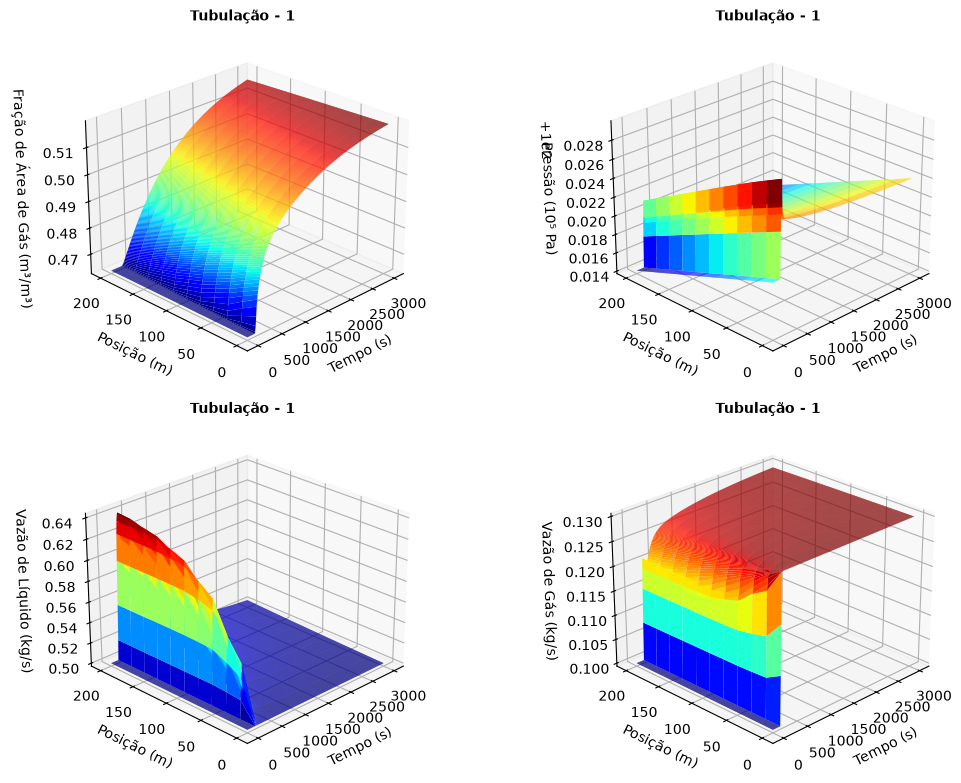

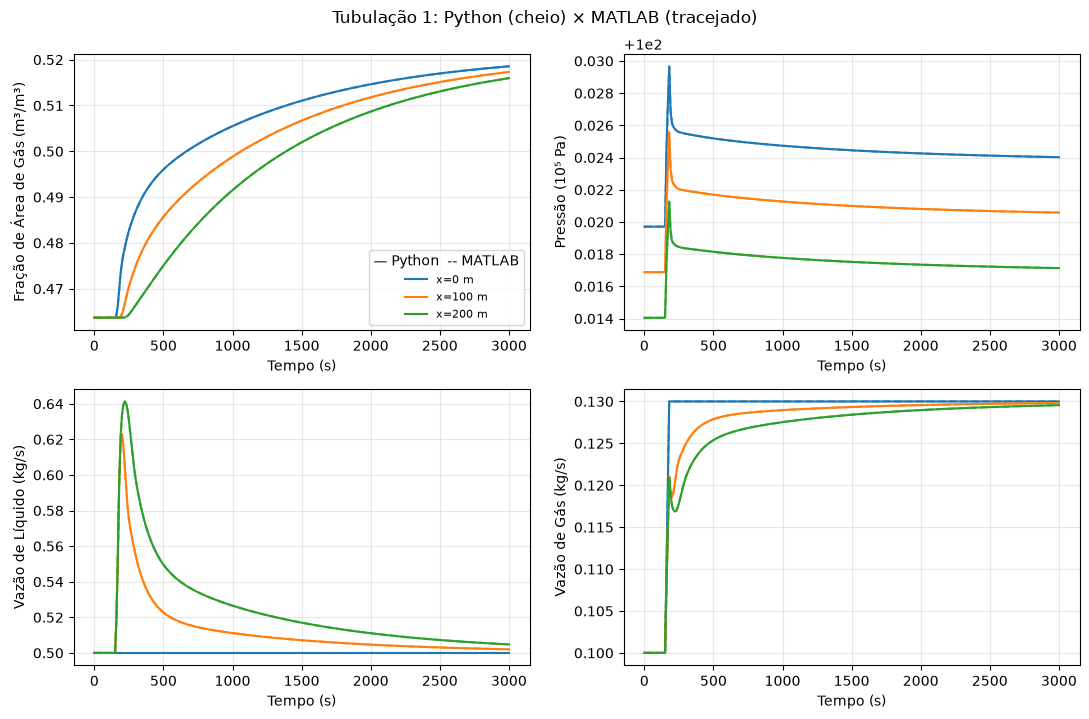

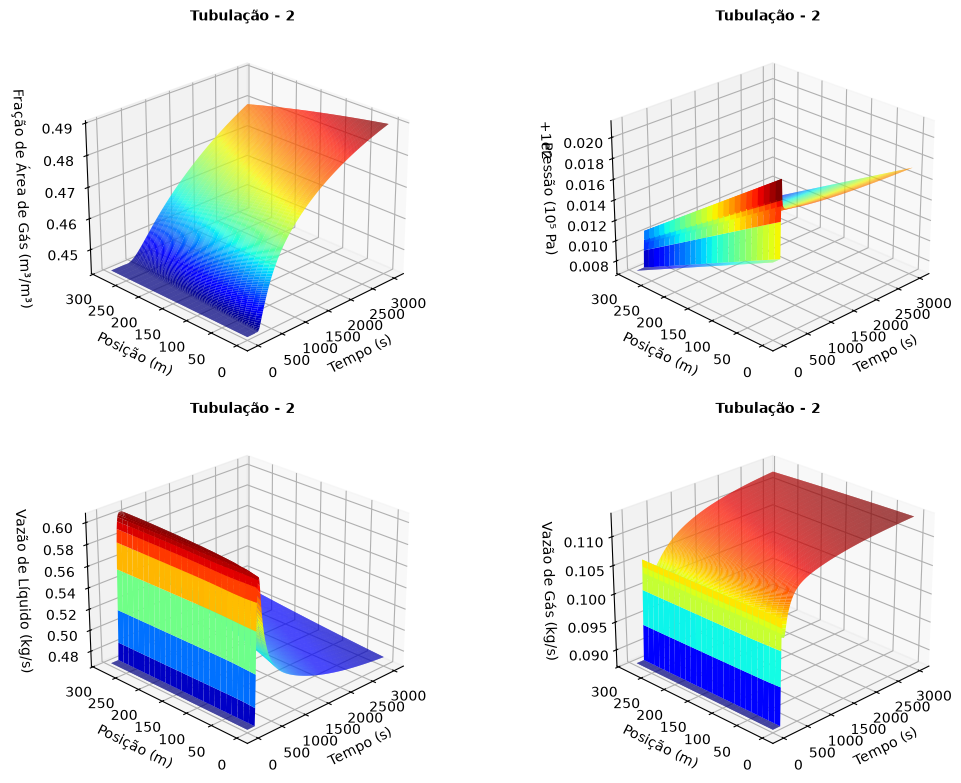

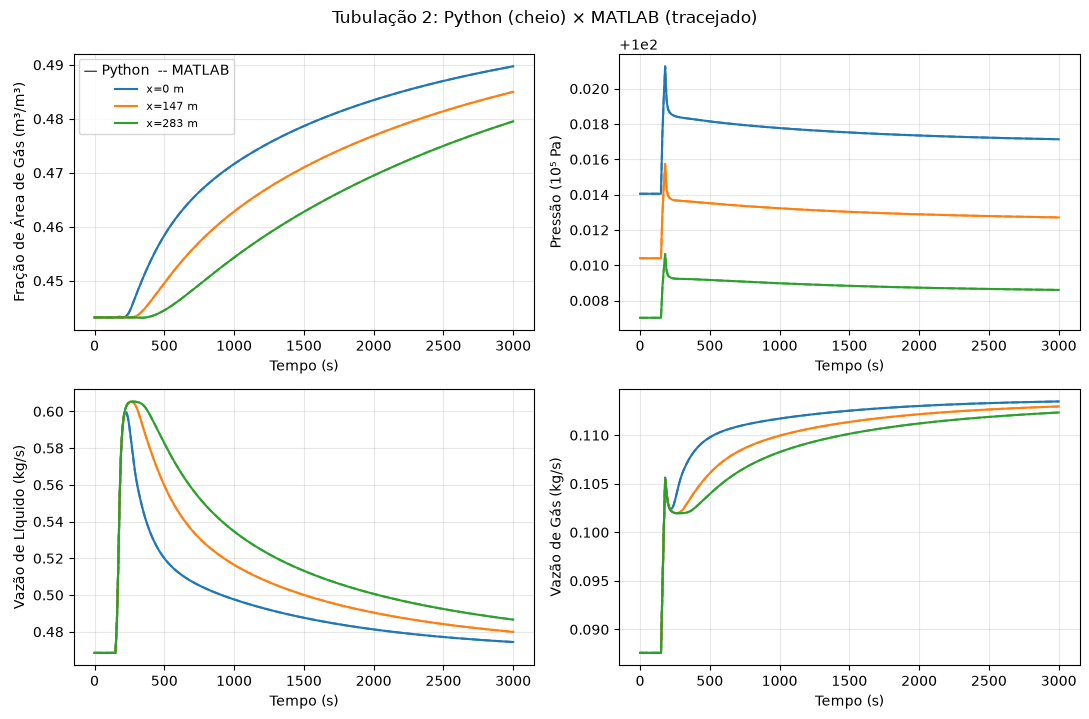

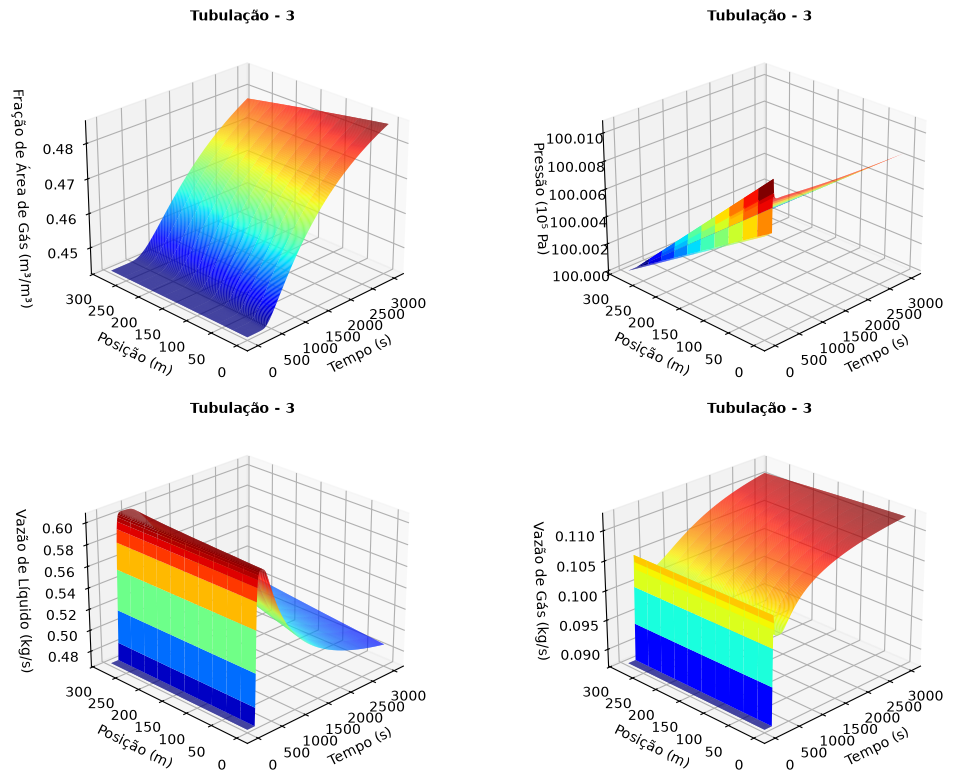

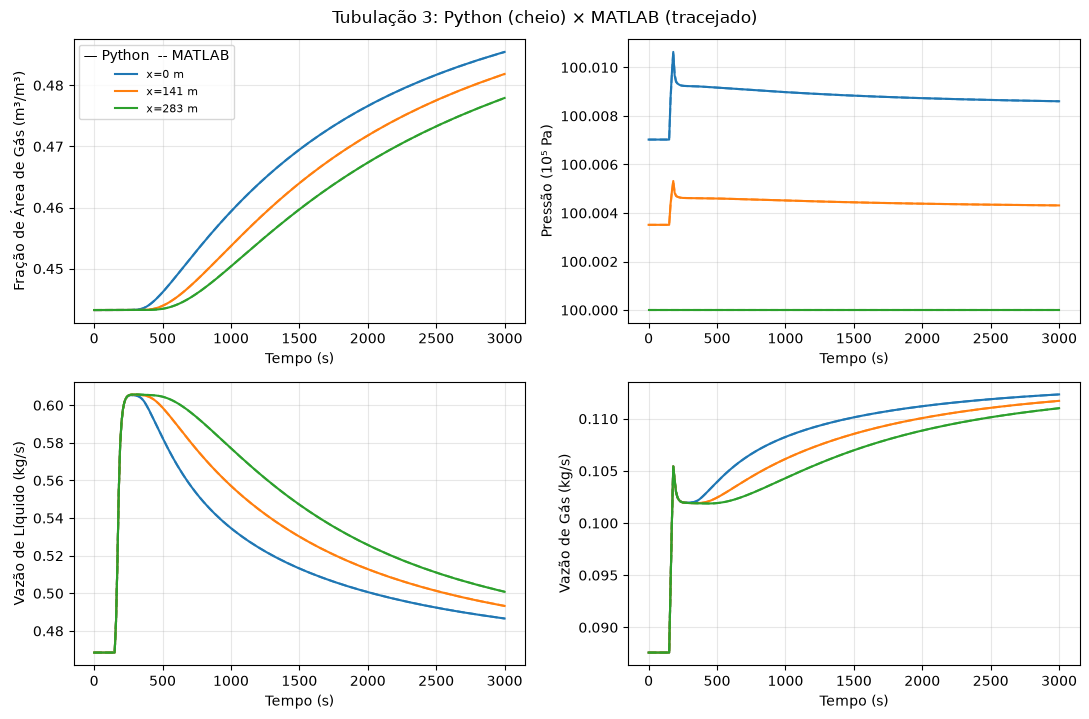

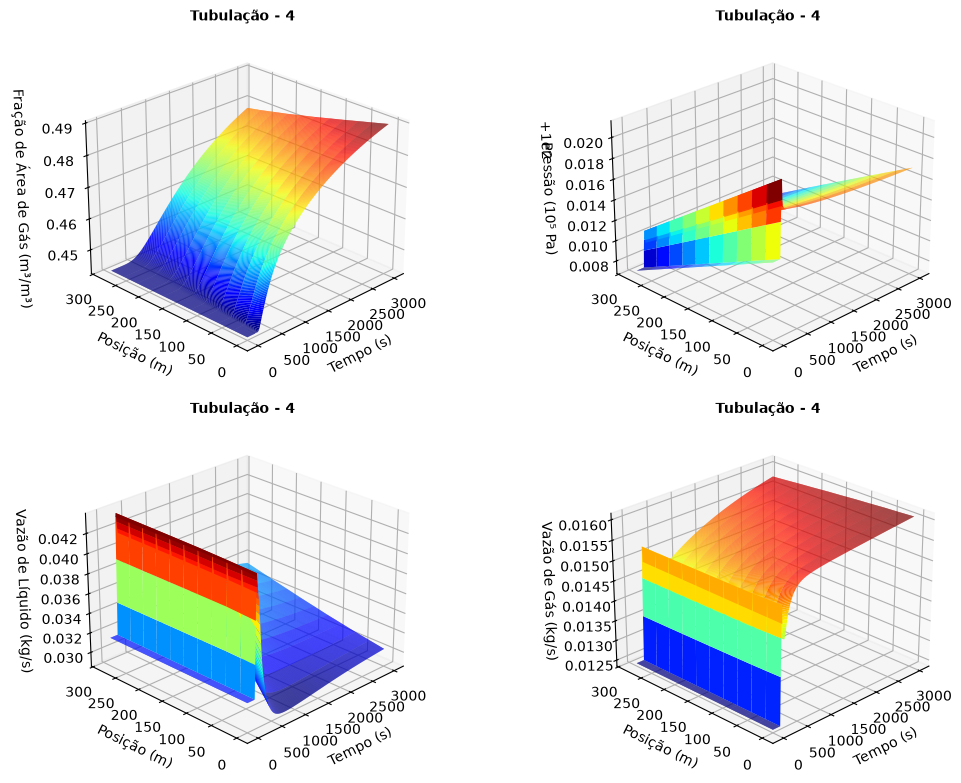

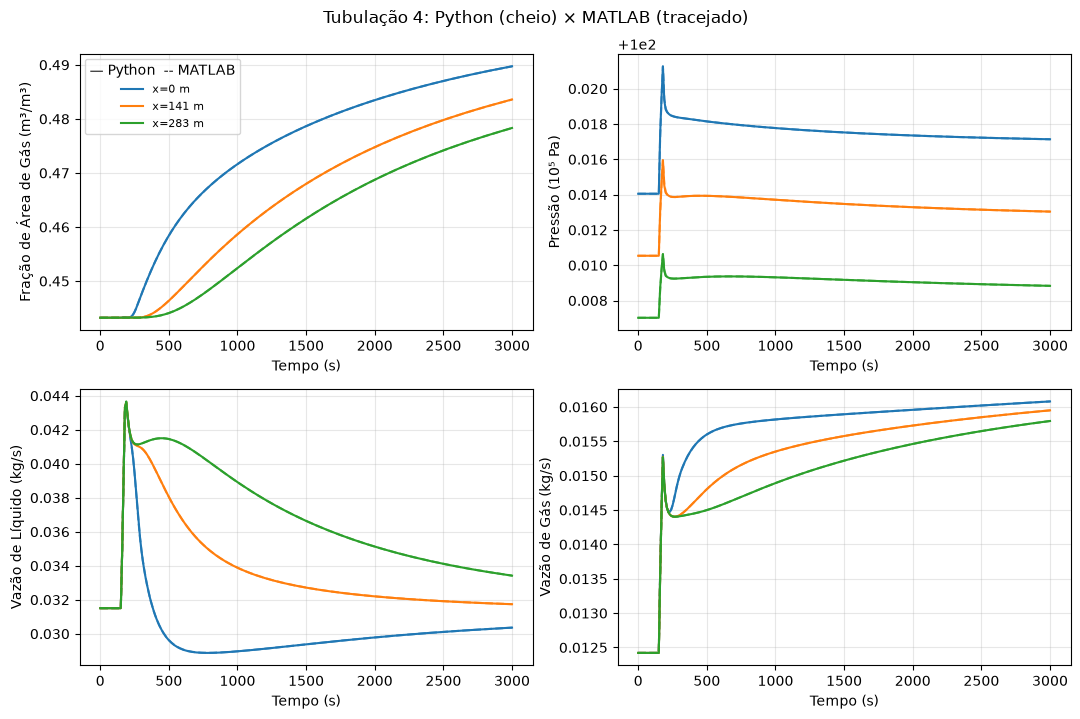

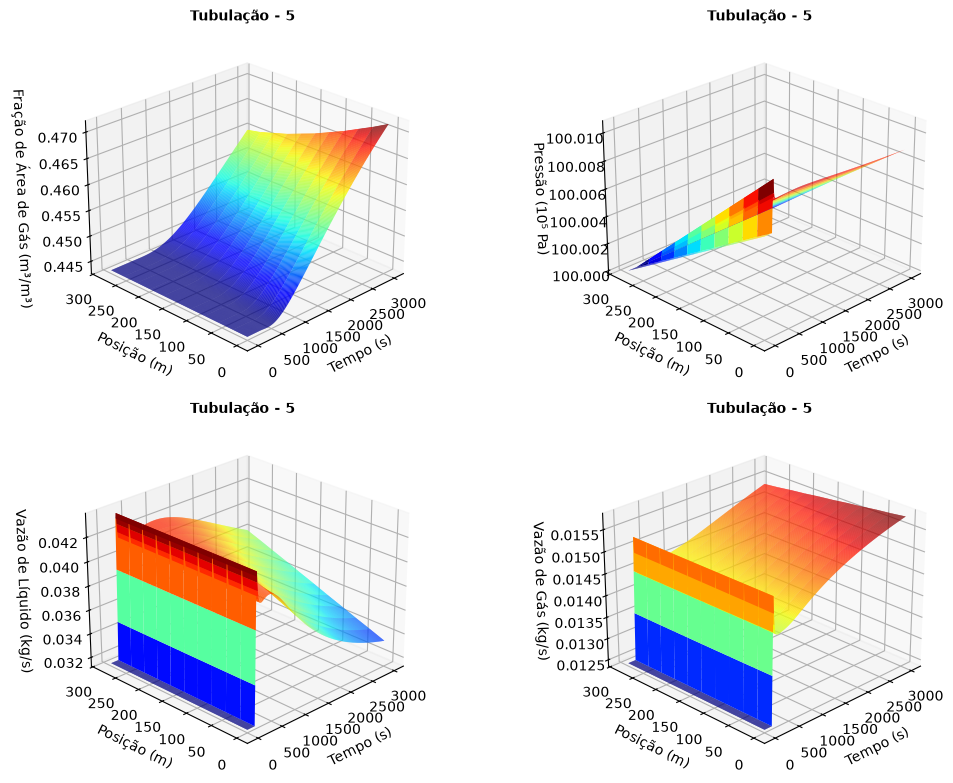

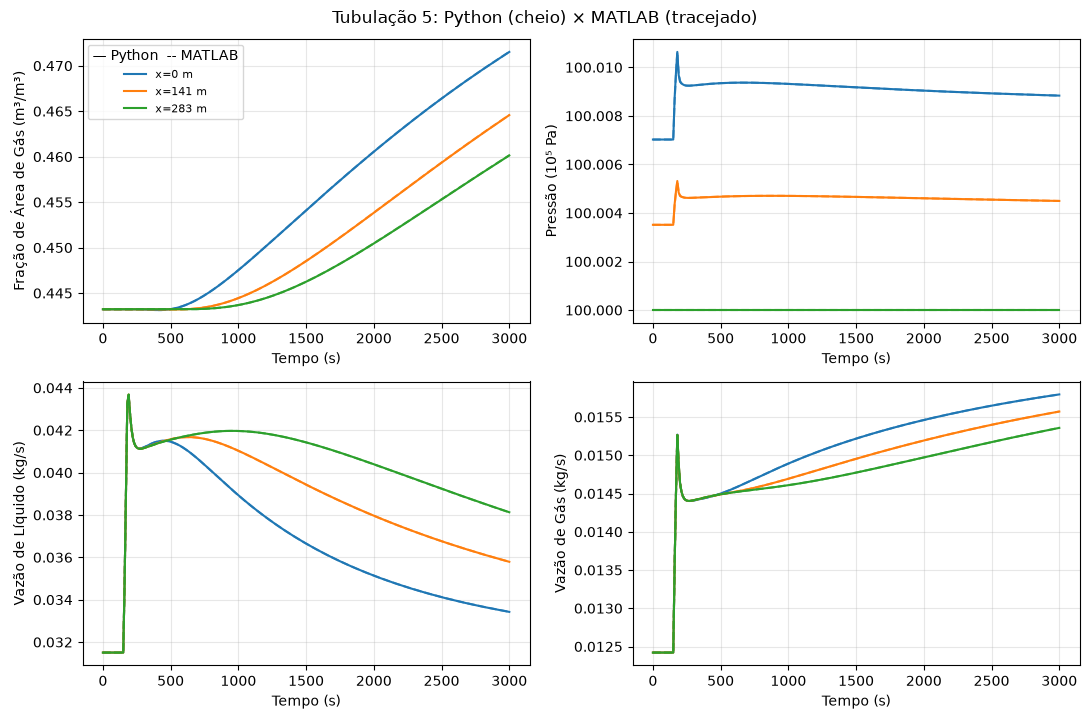

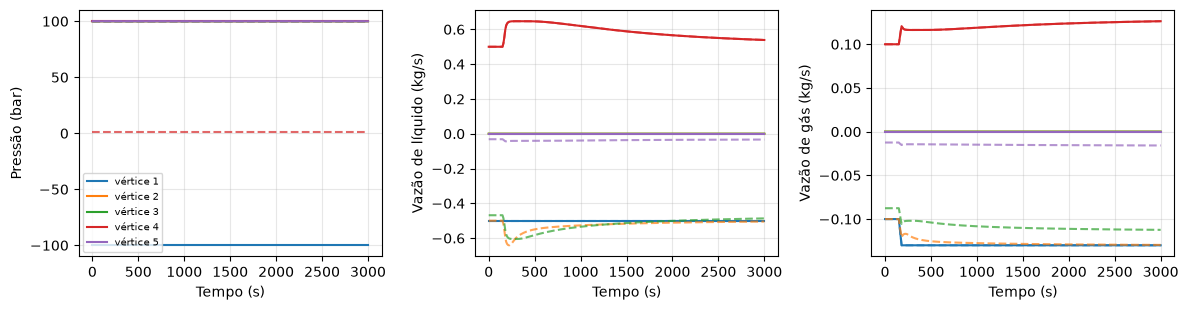

In [5]:
describe("10.2.2")
case, raw, res = run_case("10.2.2")
compare_states(res, raw)
for k in range(5):
    show_pipe(res, raw, k)
plot_vertices(res, raw)

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/jaxrhs.py`),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [6]:
from mfsim.notebook_utils import jax_comparison
res_jax = jax_comparison(case, res, rtol=1e-4, atol=1e-6)

JAX: 0.56 s (176 passos; compilação 0.49 s, uma vez por modelo) | numpy: 0.75 s (176 passos) | diferença máxima relativa dos estados 2.4e-12
